# Preprocessing and PCA

This notebook prepares Fashion-MNIST features for classical machine-learning
models and applies Principal Component Analysis (PCA) for dimensionality
reduction.

PCA is fitted using training data only. Validation and official test data are
transformed using the PCA representation learned from the training set to avoid
data leakage.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data import load_idx_images, load_idx_labels
from src.preprocessing import prepare_features, create_validation_split

In [2]:
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data import load_idx_images, load_idx_labels
from src.preprocessing import prepare_features, create_validation_split

In [3]:
DATA_DIR = PROJECT_ROOT / "data" / "raw"

X_train_raw = load_idx_images(
    DATA_DIR / "train-images-idx3-ubyte.gz"
)

y_train_full = load_idx_labels(
    DATA_DIR / "train-labels-idx1-ubyte.gz"
)

X_test_raw = load_idx_images(
    DATA_DIR / "t10k-images-idx3-ubyte.gz"
)

y_test = load_idx_labels(
    DATA_DIR / "t10k-labels-idx1-ubyte.gz"
)

print("Training:", X_train_raw.shape, y_train_full.shape)
print("Test:", X_test_raw.shape, y_test.shape)

Training: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


In [4]:
X_full = prepare_features(X_train_raw)
X_test = prepare_features(X_test_raw)

print("Training features:", X_full.shape)
print("Test features:", X_test.shape)
print("Feature range:", X_full.min(), X_full.max())

Training features: (60000, 784)
Test features: (10000, 784)
Feature range: 0.0 1.0


In [5]:
X_train, X_val, y_train, y_val = create_validation_split(
    X_full,
    y_train_full,
    validation_size=0.2,
    random_state=42,
)

print("Model training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Official test:", X_test.shape, y_test.shape)

Model training: (48000, 784) (48000,)
Validation: (12000, 784) (12000,)
Official test: (10000, 784) (10000,)


In [6]:
pca_full = PCA()
pca_full.fit(X_train)
cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

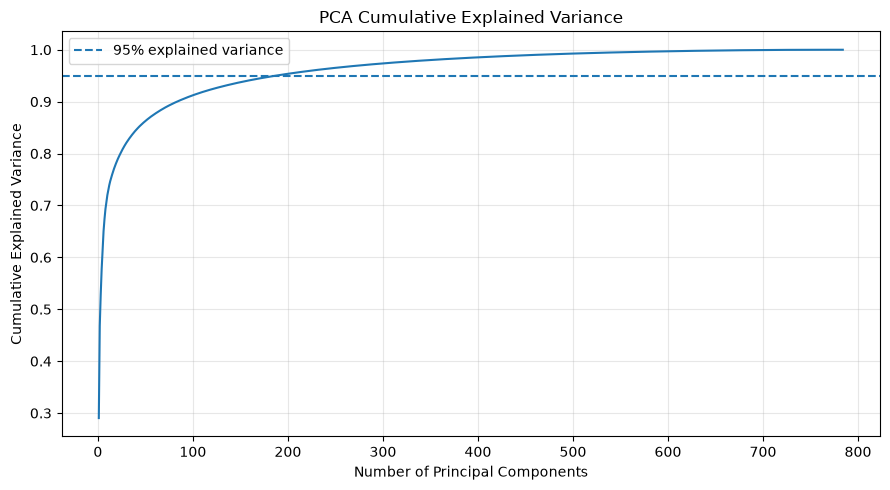

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% explained variance",
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
VARIANCE_THRESHOLD = 0.95

n_components = (
    np.argmax(cumulative_variance >= VARIANCE_THRESHOLD) + 1
)

print(
    f"Components required for {VARIANCE_THRESHOLD:.0%} variance:",
    n_components,
)

print(
    "Variance retained:",
    cumulative_variance[n_components - 1],
)

Components required for 95% variance: 187
Variance retained: 0.9500224


## PCA Component Selection

The PCA dimensionality was selected using a cumulative explained-variance
criterion.

We selected the minimum number of principal components required to retain at
least 95% of the variance in the model-training data.

This provides a reproducible rule for dimensionality selection rather than
choosing the number of components arbitrarily.

PCA was fitted only on the model-training subset. The validation and official
test sets did not influence the learned PCA representation.

In [9]:
pca = PCA(
    n_components=n_components,
    random_state=42,
)

X_train_pca = pca.fit_transform(X_train)

X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

In [10]:
print("Original feature count:", X_train.shape[1])
print("Selected PCA components:", n_components)

print()
print("Training PCA shape:", X_train_pca.shape)
print("Validation PCA shape:", X_val_pca.shape)
print("Test PCA shape:", X_test_pca.shape)

print()
print(
    "Total retained variance:",
    pca.explained_variance_ratio_.sum(),
)

Original feature count: 784
Selected PCA components: 187

Training PCA shape: (48000, 187)
Validation PCA shape: (12000, 187)
Test PCA shape: (10000, 187)

Total retained variance: 0.95002264
